# Week 2

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("../Dataset/MQTTEEB-D_cleaned_data.csv", low_memory=False)


In [28]:
print(df.isna().sum())

timestamp                   0
tcp_flags                   0
tcp_time_delta              0
tcp_len                     0
mqtt_conack_flags           0
mqtt_conflag_cleansess      0
mqtt_conflags               0
mqtt_dupflag                0
mqtt_hdrflags               0
mqtt_kalive                 0
mqtt_msg                    0
mqtt_qos                    0
label                     246
dtype: int64


Some rows have null value in "label" column.

So we will remove then, 246/222813 is not a big deal.

In [29]:
df = df.dropna()


In [30]:
print("Duplicates with time columns:", df.duplicated().sum())


Duplicates with time columns: 0


The time could create a data leakage, so we remove them. 

We store it in the df_bis

In [31]:
df_bis = df[["timestamp", "tcp_time_delta"]].copy() 
df = df.drop(columns = ["timestamp", "tcp_time_delta"])
print("duplicates without time columns:", df.duplicated().sum(), ", it represents", round(df.duplicated().mean() * 100, 1), "% of the dataset")

duplicates without time columns: 189460 , it represents 85.1 % of the dataset


The duplicates will create overfitting, so we also remove them

In [32]:
print("number of rows before dropping duplicates:", df.shape[0])
df = df.drop_duplicates()
print("number of rows after dropping duplicates:", df.shape[0])

number of rows before dropping duplicates: 222567
number of rows after dropping duplicates: 33107


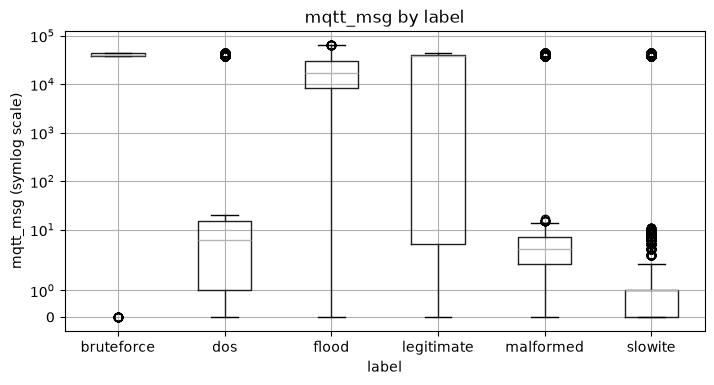

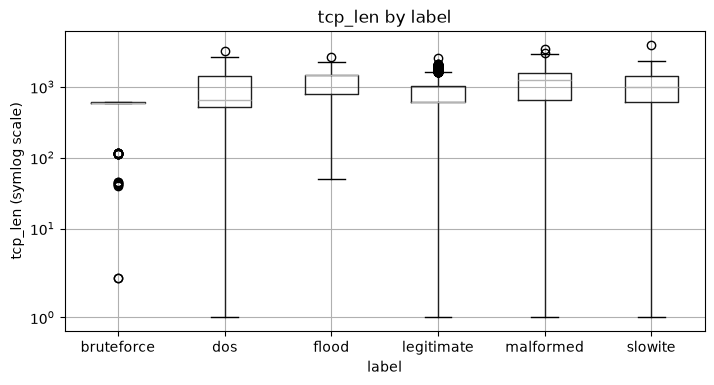

In [33]:
df.boxplot(column="mqtt_msg", by="label", figsize=(8, 4))
plt.yscale("symlog")
plt.title("mqtt_msg by label")
plt.suptitle("")
plt.ylabel("mqtt_msg (symlog scale)")
plt.show()

df.boxplot(column="tcp_len", by="label", figsize=(8, 4))
plt.yscale("symlog")
plt.title("tcp_len by label")
plt.suptitle("")
plt.ylabel("tcp_len (symlog scale)")
plt.show()

Points above the boxes are not measurement errors, they are real traffic: flood sends large payloads and legitimate traffic also produces high mqtt_msg values. Removing them would delete a large part of the legitimate class, so we keep them and rely on StandardScaler

label
malformed     14100
flood          6048
legitimate     4835
dos            4277
slowite        3675
bruteforce      172
Name: count, dtype: int64
attack packets :  85.4 % of the dataset after removing duplicates


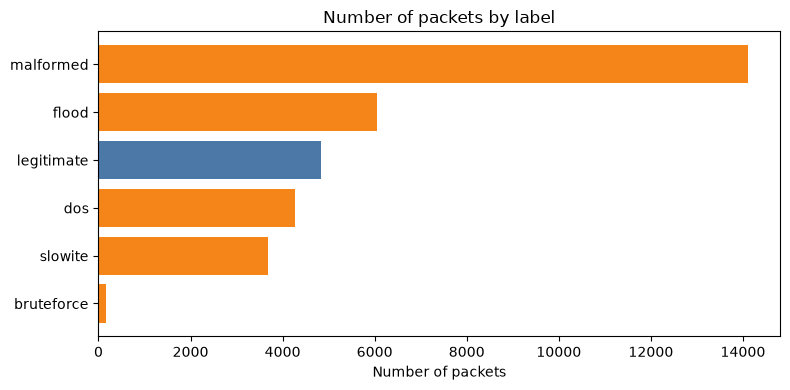

In [34]:
print(df["label"].value_counts())

attack = (df["label"] != "legitimate").mean()
print("attack packets : ", round(attack * 100, 1), "% of the dataset after removing duplicates")

counts = df["label"].value_counts().sort_values()
colors = ["#4C78A8" if label == "legitimate" else "#F58518" for label in counts.index]
plt.figure(figsize=(8, 4))
plt.barh(counts.index, counts.values, color=colors)
plt.xlabel("Number of packets")
plt.title("Number of packets by label")
plt.tight_layout()
plt.show()

A classifier that always predicts “attack” has 85,4% accuracy, so we use balanced accuracy and recall.

The model cannot work with hexadecimal, so we convert it in decimal.

Finally we convert the decimal number to strings; this won't be passed to the model, it's only for our own understanding. 

In [35]:
tcp_flags_strings_list = []
tcp_flags_int_list = []
for i in df["tcp_flags"]:
    tcp_flags_entier = int(f"{i}", 16)
    tcp_flags_int_list.append(tcp_flags_entier)
    tcp_flags_strings = ""

    if tcp_flags_entier >= 128: 
        tcp_flags_strings += "CWR "
        tcp_flags_entier -= 128
    if tcp_flags_entier >= 64: 
        tcp_flags_strings += "ECE "
        tcp_flags_entier -= 64
    if tcp_flags_entier >= 32: 
        tcp_flags_strings += "URG "
        tcp_flags_entier -= 32
    if tcp_flags_entier >= 16: 
        tcp_flags_strings += "ACK "
        tcp_flags_entier -= 16
    if tcp_flags_entier >= 8: 
        tcp_flags_strings += "PSH "
        tcp_flags_entier -= 8
    if tcp_flags_entier >= 4: 
        tcp_flags_strings += "RST "
        tcp_flags_entier -= 4
    if tcp_flags_entier >= 2: 
        tcp_flags_strings += "SYN "
        tcp_flags_entier -= 2
    if tcp_flags_entier == 1: 
        tcp_flags_strings += "FIN "
        tcp_flags_entier -= 1
    tcp_flags_strings_list.append(tcp_flags_strings)


df["tcp_flags_int"] = tcp_flags_int_list
df_bis = df_bis.loc[df.index].copy()
df_bis["tcp_flags_strings"] = tcp_flags_strings_list
df = df.drop(columns = ["tcp_flags"])

In [36]:
hex_cols = ["mqtt_hdrflags", "mqtt_conflags", "mqtt_conack_flags"]

for col in hex_cols:
    df[col] = df[col].astype(str).apply(lambda x: int(x, 16))

Here we don't want to predict which type of attack we have detect, we just want to detect if the row is an attack or legitimate. 

In [37]:
target = []
for l in df["label"]:
    if l != "legitimate":
        target.append(1)
    else: 
        target.append(0)

df["target"] = target
df_bis["label"] = df["label"]
df = df.drop(columns = ["label"])

OUT_PATH = "../Dataset/MQTTEEB-D_int.csv"
df.to_csv(OUT_PATH, index=False)
print(f"Fichier enregistré : {OUT_PATH}")

Fichier enregistré : ../Dataset/MQTTEEB-D_int.csv


In [38]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75, stratify=y, random_state=42)

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, f1_score, confusion_matrix
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

scaler = StandardScaler()
X_train_stand = scaler.fit_transform(X_train)
X_test_stand = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_stand, y_train)

y_pred = model.predict(X_test_stand)

print(confusion_matrix(y_test, y_pred))
print("Accuracy: ", accuracy_score(y_test,y_pred))
print("Balanced accuracy: ", balanced_accuracy_score(y_test,y_pred))
print("F1 - score: ", f1_score(y_test,y_pred))
print("Precision", precision_score (y_test , y_pred))
print("Recall", recall_score (y_test , y_pred))


[[ 725  484]
 [1185 5883]]


Accuracy:  0.798356892593935
Balanced accuracy:  0.7160060511079187
F1 - score:  0.8757722366951991
Precision 0.9239830375373017
Recall 0.8323429541595926



We cannot trust accuracy, because in an imbalanced dataset, the accuracy is not a good representation (it is the same for precision and recall, because it is with the majority class). So the best metric here is the balanced accuracy.